# G1.3 · Counting FLOPs, measuring MFU, estimating training cost

**ID:** G1.3 · **Target:** 90 min · **Plan week:** 4 (FLOP/param counting, sections 1-2), 15 (MFU and the 7B estimate) · **Part:** G1

**The lab.** Derive the FLOPs of a transformer from its matmuls, check your count *exactly* against
`torch.utils.flop_counter.FlopCounterMode` on `tinygpt`, measure training throughput and **model FLOPs
utilization (MFU)** on this RTX 3090, then answer the guide's mock question: *"Estimate memory and FLOPs for
training a 7B model on N tokens"* (memory is in G1.2), as GPU-hours with a stated MFU.

Fill in every `raise NotImplementedError`. Solution runtime: about 1 min.

## Sources
- J. Kaplan et al., *Scaling Laws for Neural Language Models*, 2020, arXiv:2001.08361 (Table 1: per-token forward
  FLOPs, $C_\text{forward} \approx 2N + 2n_\text{layer}n_\text{ctx}d_\text{attn}$; $C \approx 6N$ per training token) — https://arxiv.org/abs/2001.08361
- A. Chowdhery et al., *PaLM: Scaling Language Modeling with Pathways*, JMLR 2023, arXiv:2204.02311 (§4.1 and
  Appendix B: MFU definition, $6N + 12LHQT$ FLOPs per token, A100 312 peak matmul TFLOP/s) — https://arxiv.org/abs/2204.02311
- J. Hoffmann et al., *Training Compute-Optimal Large Language Models* (Chinchilla), NeurIPS 2022,
  arXiv:2203.15556 (70B params on 1.4T tokens, about 20 tokens per parameter) — https://arxiv.org/abs/2203.15556
- H. Touvron et al., *Llama 2: Open Foundation and Fine-Tuned Chat Models*, 2023, arXiv:2307.09288 (Table 1: 7B,
  4k context, 2.0T tokens; Table 2: 184,320 A100-80GB GPU-hours for 7B) — https://arxiv.org/abs/2307.09288
- Q. Anthony, S. Biderman, H. Schoelkopf, *Transformer Math 101*, EleutherAI blog, 2023 ($C \approx 6PD$) —
  https://blog.eleuther.ai/transformer-math/
- V. Korthikanti et al., arXiv:2205.05198 (hardware FLOPs vs model FLOPs under recomputation) — https://arxiv.org/abs/2205.05198
- J. Austin et al., *How to Scale Your Model*, 2025, "All the Transformer Math You Need to Know" —
  https://jax-ml.github.io/scaling-book/transformers/ ; "How to Think About GPUs" (H100 9.9e14 bf16 FLOP/s,
  A100 3.1e14) — https://jax-ml.github.io/scaling-book/gpus/
- NVIDIA GA102 whitepaper v2, Appendix A Table 9 (RTX 3090: 71 TFLOPS bf16/fp16 tensor with FP32 accumulate,
  35.6 TF32, 35.6 FP32) — https://www.nvidia.com/content/PDF/nvidia-ampere-ga-102-gpu-architecture-whitepaper-v2.pdf
- PyTorch `torch.utils.flop_counter.FlopCounterMode` (source: https://github.com/pytorch/pytorch/blob/main/torch/utils/flop_counter.py)
- S. Raschka, *LLMs-from-scratch*, `ch04/02_performance-analysis/flops-analysis.ipynb` (Apache-2.0, local copy
  `../../LLMs-from-scratch/ch04/02_performance-analysis/flops-analysis.ipynb`, commit f9313ea): FLOPs with `thop` and
  an MFU-style throughput benchmark for GPT-2 sizes; a good companion read.
- Stanford CS336 Spring 2026 A2 handout §2.1.2-2.1.3 (model sizes, end-to-end benchmarking) — https://github.com/stanford-cs336/assignment2-systems @ca8bc81 (MIT)

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.flop_counter import FlopCounterMode

from prep import Session, check, check_close, seed_everything
from prep.tinygpt import GPT, GPTConfig, num_params, random_batch

s = Session("G1.3", target_min=90)
seed_everything(0)
dev = torch.device("cuda")
PEAK = {"fp32": 35.6e12, "tf32": 35.6e12, "bf16": 71e12}  # GA102 whitepaper Table 9, dense, FP32 accumulate


def count_flops(fn):
    """FLOPs that FlopCounterMode attributes to matmul-like ops (mm, addmm, bmm, SDPA, conv) while running fn()."""
    with FlopCounterMode(display=False) as fc:
        fn()
    return fc.get_total_flops()

[G1.3] started 16:50; target 90 min


## 1. FLOPs of a matmul and of a linear layer's training step

$C = AB$ with $A\in\mathbb{R}^{m\times k}$, $B\in\mathbb{R}^{k\times n}$: each of the $mn$ outputs is a dot product
of length $k$: $k$ multiplies and $k-1$ adds, so **$2mnk$ FLOPs** (one multiply-accumulate = 2 FLOPs; `thop` and
some papers count MACs, half as many).

For a linear layer $Y = XW$ ($X$: $B\times d_\text{in}$, $W$: $d_\text{in}\times d_\text{out}$) the backward needs
two more matmuls of the same size: $\partial X = \partial Y\,W^\top$ and $\partial W = X^\top \partial Y$. So training
costs $3\times$ the forward, $6\,B\,d_\text{in}d_\text{out}$: **6 FLOPs per parameter per token** (2 forward + 4
backward). The first layer of a network skips $\partial X$ when its input does not require grad.

**Exercise 1.1.**

In [2]:
def matmul_flops(m, n, k):
    return 2 * m * n * k


def linear_train_flops(B, d_in, d_out, input_requires_grad=True):
    """Forward + backward FLOPs of x @ W for x: (B, d_in). Bias ignored."""
    fwd = 2 * B * d_in * d_out
    return fwd + fwd + (fwd if input_requires_grad else 0)  # forward, dW, dX


a, b = torch.randn(64, 96, device=dev), torch.randn(96, 80, device=dev)
check("matmul FLOPs vs FlopCounterMode", matmul_flops(64, 80, 96) == count_flops(lambda: a @ b))
lin = nn.Linear(256, 512, bias=False).to(dev)
for rg in (True, False):
    xin = torch.randn(32, 256, device=dev, requires_grad=rg)
    check(f"linear fwd+bwd FLOPs (input requires_grad={rg})",
          linear_train_flops(32, 256, 512, rg) == count_flops(lambda: lin(xin).sum().backward()))

ok  matmul FLOPs vs FlopCounterMode
ok  linear fwd+bwd FLOPs (input requires_grad=True)
ok  linear fwd+bwd FLOPs (input requires_grad=False)


## 2. FLOPs of a transformer, per token

Per layer with model width $d$, MLP width $4d$, context $T$ (Kaplan et al. Table 1; ignore biases, norms,
nonlinearities, softmax: they are $O(d)$ per token, tiny next to $O(d^2)$):

| piece | weights | forward FLOPs per token |
| --- | --- | --- |
| QKV projection | $3d^2$ | $6d^2$ |
| $QK^\top$ (scores against $T$ keys) | – | $2Td$ |
| $PV$ | – | $2Td$ |
| output projection | $d^2$ | $2d^2$ |
| MLP | $8d^2$ | $16d^2$ |
| **layer total** | $12d^2$ | $24d^2 + 4Td$ |

plus the LM head, $2dV$ per token. With $N$ = weights that take part in matmuls, forward $\approx 2N + 4LTd$ and
training $\approx 6N + 12LTd$ per token, exactly PaLM's $6N + 12LHQT$ ($HQ = d$). Two conventions to watch:
- Kaplan's $N$ excludes embeddings, and his Table 1 row "Attention: Mask" counts $2n_\text{layer}n_\text{ctx}d$, i.e.
  only one of the two $T$-dependent matmuls. PaLM counts both. State which you use.
- With a causal mask half of the $T\times T$ scores are never needed (FlashAttention skips them), but the MFU
  convention still counts the full $12LTd$.
- A **tied** LM head reuses the embedding matrix, but the head matmul still costs $2dV$ forward and $6dV$ training per
  token. For small models with big vocabularies this term is large: tinygpt's head has more weights than its blocks.

**Exercise 2.1.** `matmul_params(cfg)`: number of weights used in matmuls (blocks + LM head; position embeddings are
a lookup, not a matmul). `train_flops_per_token(cfg)`: $6N + 12LTd$ with $T$ = `cfg.context_length`.

In [3]:
def matmul_params(cfg):
    return 12 * cfg.n_layers * cfg.d_model**2 + cfg.d_model * cfg.vocab_size


def train_flops_per_token(cfg):
    return 6 * matmul_params(cfg) + 12 * cfg.n_layers * cfg.context_length * cfg.d_model


cfg = GPTConfig(sdpa=False)
model = GPT(cfg).to(dev)
lin_weights = sum(m.weight.numel() for m in model.modules() if isinstance(m, nn.Linear) and m is not model.head)
check("matmul_params = Linear weights in blocks + head", matmul_params(cfg) == lin_weights + model.head.weight.numel())
print(f"tinygpt: total params {num_params(model) / 1e6:.2f} M, non-embedding (Kaplan N) "
      f"{num_params(model, non_embedding=True) / 1e6:.2f} M, matmul weights {matmul_params(cfg) / 1e6:.2f} M")

Bsz = 4
xb, yb = random_batch(cfg, Bsz, dev)
tokens = Bsz * cfg.context_length


def fwd_bwd(m):
    def f():
        _, loss = m(xb, yb)
        loss.backward()
    return f


fwd_counted = count_flops(lambda: model(xb, yb))
train_counted = count_flops(fwd_bwd(model))
fwd_pred = tokens * (2 * matmul_params(cfg) + 4 * cfg.n_layers * cfg.context_length * cfg.d_model)
print(f"forward:  counted {fwd_counted:.4e}  predicted {fwd_pred:.4e}")
print(f"training: counted {train_counted:.4e}  predicted {tokens * train_flops_per_token(cfg):.4e}")
print(f"naive '6 x Kaplan N' would predict {tokens * 6 * num_params(model, non_embedding=True):.4e} "
      f"({6 * num_params(model, non_embedding=True) / train_flops_per_token(cfg):.0%} of the true count)")
check("forward FLOPs match FlopCounterMode exactly (explicit attention)", fwd_counted == fwd_pred)
check("training FLOPs match FlopCounterMode exactly (explicit attention)", train_counted == tokens * train_flops_per_token(cfg))

ok  matmul_params = Linear weights in blocks + head
tinygpt: total params 30.04 M, non-embedding (Kaplan N) 10.64 M, matmul weights 29.92 M


forward:  counted 6.3683e+10  predicted 6.3683e+10
training: counted 1.9105e+11  predicted 1.9105e+11
naive '6 x Kaplan N' would predict 6.5362e+10 (34% of the true count)
ok  forward FLOPs match FlopCounterMode exactly (explicit attention)
ok  training FLOPs match FlopCounterMode exactly (explicit attention)


In [4]:
# The same model with fused SDPA attention: FlopCounterMode's formula for the memory-efficient attention backward
# includes recomputing QK^T (5 matmuls instead of 4), so it reports *hardware* FLOPs, slightly above model FLOPs.
model_sdpa = GPT(GPTConfig(sdpa=True)).to(dev)
c = count_flops(fwd_bwd(model_sdpa))
print(f"sdpa training: counted {c:.4e}  model FLOPs {tokens * train_flops_per_token(cfg):.4e}  ratio {c / (tokens * train_flops_per_token(cfg)):.4f}")
check("SDPA count = model FLOPs + one recomputed QK^T per layer",
      c == tokens * train_flops_per_token(cfg) + cfg.n_layers * tokens * 2 * cfg.context_length * cfg.d_model)
del model, model_sdpa

sdpa training: counted 1.9226e+11  model FLOPs 1.9105e+11  ratio 1.0063
ok  SDPA count = model FLOPs + one recomputed QK^T per layer


## 3. Measure throughput and MFU on this GPU

**MFU** (PaLM §4.1) = achieved model FLOP/s ÷ peak FLOP/s = $\text{tokens/s} \times \text{FLOPs/token} \,/\, P$.
"Model FLOPs" are what the architecture needs ($6N + 12LTd$), *not* what the hardware executes: recomputation for
activation checkpointing adds a forward ($8N$ executed for $6N$ counted), which counts in **HFU** (hardware FLOPs
utilization) but not in MFU. Use the peak for the dtype you run: 71 TFLOPS for bf16 on a 3090 (not 142, G1.1).

**Exercise 3.1.** `mfu(tokens_per_s, flops_per_token, peak)`. **Predict** before running: tinygpt in fp32, tf32,
bf16; a GPT-2-small shape ($d=768$, $L=12$, $T=1024$) in bf16.

ok  MFU arithmetic


tinygpt fp32                 78938 tokens/s   MFU 41.4% of 35.6 TFLOPS (14.7 TFLOP/s achieved)


tinygpt tf32                 99932 tokens/s   MFU 52.4% of 35.6 TFLOPS (18.6 TFLOP/s achieved)


tinygpt bf16                150634 tokens/s   MFU 39.6% of 71.0 TFLOPS (28.1 TFLOP/s achieved)


GPT-2-small shape bf16       54811 tokens/s   MFU 66.0% of 71.0 TFLOPS (46.8 TFLOP/s achieved)


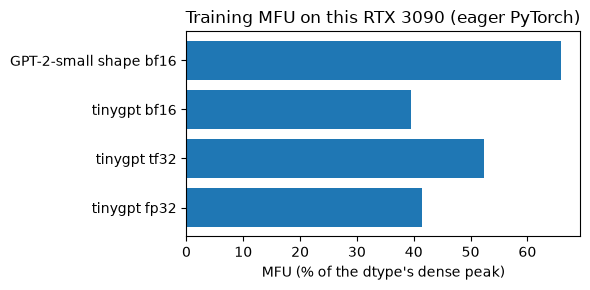

ok  bf16 is faster than fp32 in tokens/s
ok  MFU values are physical (0 < MFU <= 1.1)


In [5]:
def mfu(tokens_per_s, flops_per_token, peak):
    return tokens_per_s * flops_per_token / peak


check_close("MFU arithmetic", mfu(1e5, 1e9, 2e14), 0.5)


def measure(cfg, B, dtype_name, steps=8, warmup=3):
    torch.manual_seed(0)
    m = GPT(cfg).to(dev)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4, fused=True)
    x, y = random_batch(cfg, B, dev)
    torch.backends.cuda.matmul.fp32_precision = "tf32" if dtype_name == "tf32" else "ieee"
    amp = dtype_name == "bf16"

    def step():
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=amp):
            _, loss = m(x, y)
        loss.backward()
        opt.step()
        opt.zero_grad(set_to_none=True)

    for _ in range(warmup):
        step()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(steps):
        step()
    torch.cuda.synchronize()
    dt = (time.perf_counter() - t0) / steps
    torch.backends.cuda.matmul.fp32_precision = "ieee"
    tps = B * cfg.context_length / dt
    return tps, mfu(tps, train_flops_per_token(cfg), PEAK[dtype_name])


runs = [("tinygpt fp32", GPTConfig(), 16, "fp32"), ("tinygpt tf32", GPTConfig(), 16, "tf32"),
        ("tinygpt bf16", GPTConfig(), 16, "bf16"),
        ("GPT-2-small shape bf16", GPTConfig(d_model=768, n_heads=12, n_layers=12, context_length=1024), 8, "bf16")]
res = {}
for name, c_, B, dt_ in runs:
    res[name] = measure(c_, B, dt_)
    print(f"{name:24s} {res[name][0]:9.0f} tokens/s   MFU {res[name][1]:.1%} of {PEAK[dt_] / 1e12:.1f} TFLOPS "
          f"({res[name][0] * train_flops_per_token(c_) / 1e12:.1f} TFLOP/s achieved)")
plt.figure(figsize=(6, 3))
plt.barh(list(res), [100 * v[1] for v in res.values()])
plt.xlabel("MFU (% of the dtype's dense peak)"); plt.title("Training MFU on this RTX 3090 (eager PyTorch)")
plt.tight_layout(); plt.show()
check("bf16 is faster than fp32 in tokens/s", res["tinygpt bf16"][0] > 1.5 * res["tinygpt fp32"][0])
check("MFU values are physical (0 < MFU <= 1.1)", all(0 < v[1] <= 1.1 for v in res.values()))

Why the bigger model has higher MFU: its matmuls are larger (better tensor-core efficiency, G1.1 §5), and the
non-matmul work (LayerNorm, GELU, softmax, the optimizer, kernel launches) is a smaller fraction of the step. MFU of
40-60% is typical for well-tuned large-scale training; PaLM reported 46.2% on TPU v4 (Chowdhery et al. Table 3).
`torch.compile` raises small-model MFU by fusing the pointwise ops (G1.6).

## 4. The interview estimate: GPU-hours to train a 7B model

$C \approx 6ND$ (+ attention), time $= C / (\text{GPUs} \times P \times \text{MFU})$.

**Exercise 4.1.** `train_gpu_hours(n_params, n_tokens, peak, mfu, attn_flops_per_token=0)` and the inverse,
`implied_mfu(...)`: the MFU that a reported GPU-hour count implies.

**Calibrate on a public number.** Llama 2 7B: 2.0T tokens at 4k context, 184,320 A100-80GB GPU-hours (Touvron et al.
Tables 1-2); A100 peak 312 TFLOPS bf16 (PaLM App. B). Its attention term is $12LTd = 12\cdot32\cdot4096\cdot4096$.

In [6]:
def train_gpu_hours(n_params, n_tokens, peak, mfu, attn_flops_per_token=0.0):
    total = n_tokens * (6 * n_params + attn_flops_per_token)
    return total / (peak * mfu) / 3600


def implied_mfu(n_params, n_tokens, gpu_hours, peak, attn_flops_per_token=0.0):
    return n_tokens * (6 * n_params + attn_flops_per_token) / (gpu_hours * 3600 * peak)


attn_llama = 12 * 32 * 4096 * 4096
m6 = implied_mfu(7e9, 2.0e12, 184_320, 312e12)
m6a = implied_mfu(7e9, 2.0e12, 184_320, 312e12, attn_llama)
print(f"Llama 2 7B implied MFU: {m6:.1%} (6ND only), {m6a:.1%} (with attention)")
check_close("implied MFU, 6ND", m6, 6 * 7e9 * 2e12 / (184_320 * 3600 * 312e12), atol=0, rtol=1e-9)
check_close("round trip", train_gpu_hours(7e9, 2e12, 312e12, m6a, attn_llama), 184_320, atol=0, rtol=1e-9)

mfu_3090 = res["GPT-2-small shape bf16"][1]
chin = 20 * 7e9  # Chinchilla-optimal tokens for 7B (~20 tokens / parameter)
for label, peak, u in (("A100, 40% MFU", 312e12, 0.40), ("RTX 3090, measured GPT-2-small MFU", 71e12, mfu_3090)):
    h = train_gpu_hours(7e9, chin, peak, u, attn_llama)
    print(f"7B on {chin / 1e9:.0f}B tokens, {label}: {h:,.0f} GPU-hours = {h / 24 / 1024:.1f} days on 1024 GPUs")

Llama 2 7B implied MFU: 40.6% (6ND only), 46.8% (with attention)
ok  implied MFU, 6ND
ok  round trip
7B on 140B tokens, A100, 40% MFU: 15,095 GPU-hours = 0.6 days on 1024 GPUs
7B on 140B tokens, RTX 3090, measured GPT-2-small MFU: 40,226 GPU-hours = 1.6 days on 1024 GPUs


**How to say it in an interview.** "7B × 1.4T tokens × 6 ≈ 6×10²² FLOPs, plus ~15% for attention at 4k context. An
A100 gives 312 TFLOPS peak; at 40% MFU that's 125 TFLOP/s, so ≈ 5×10⁸ GPU-seconds ≈ 150k GPU-hours, about a week on
1,000 GPUs. Sanity check: Meta reports 184k A100-hours for Llama 2 7B on 2T tokens, which implies ~40-45% MFU." And
for memory: 16 bytes/param → 112 GB of states, so ZeRO-3/FSDP across ≥ 8 GPUs (G1.2). On RTX 3090s the compute alone
would be about 400k GPU-hours for 1.4T tokens (40k for the Chinchilla-optimal 140B computed above), and 24 GB per card plus PCIe-only communication make it impractical.

## Say it out loud
1. Why 2 FLOPs per multiply-accumulate, and why is training $\approx 3\times$ the forward? Where does "6N" come from?
2. Derive the per-token FLOPs of one transformer layer. When does the attention term $12LTd$ matter compared to $6N$?
3. Why does "6 × non-embedding parameters" undercount tinygpt by almost 3×?
4. Define MFU and HFU. Your run uses activation checkpointing: what happens to each?
5. Your MFU is 15%. Where would you look first?
6. Estimate GPU-hours to train a 7B model on 1T tokens on H100s at 40% MFU (H100 dense bf16 ≈ 990 TFLOPS: *How to Scale Your Model*, GPU chapter table, 9.9e14 FLOP/s).

<details><summary>Model answers</summary>

1. A dot product of length $k$ is $k$ multiplies + ($k-1$) adds ≈ $2k$. Backward of $Y=XW$ needs $\partial X = \partial Y W^\top$ and
   $\partial W = X^\top\partial Y$, each the size of the forward matmul, so 3× in total; 2 forward + 4 backward FLOPs per weight per
   token (Kaplan et al. 2020; PaLM App. B).
2. $24d^2 + 4Td$ forward ($6d^2$ QKV, $2d^2$ output projection, $16d^2$ MLP, $2Td$ each for $QK^\top$ and $PV$), so $72d^2+12Td$ training.
   The attention part is comparable when $12Td \approx 72d^2$, i.e. $T \approx 6d$. Kaplan phrases it as $d_\text{model} > n_\text{ctx}/12$ for
   his one-matmul convention. For a 7B model ($d=4096$, $L=32$) at $T=4096$ it is +15%; at 32k context it exceeds the weight FLOPs.
3. tinygpt's LM head is a $384 \times 50257$ matmul (19.3M weights vs 10.6M in the blocks). Being tied to the embedding, it is
   excluded from Kaplan's non-embedding $N$, but it still costs $6dV$ per token, so most of the FLOPs are uncounted.
4. MFU = model FLOPs/s ÷ peak, where model FLOPs are what the architecture requires ($6N+12LTd$ per token). HFU counts what the
   hardware executes, including recomputation. With full checkpointing the hardware does one more forward, about $8N$ per token:
   HFU rises to about 4/3 of MFU at the same wall-clock speed, while MFU drops if the step got slower. MFU is the
   implementation-independent number (PaLM §4.1).
5. Check the peak you divide by (dtype, accumulate mode, clock). Then profile (G1.6): idle gaps between kernels (overhead-bound: small
   batch or model, Python; fix with larger micro-batch, `torch.compile`, CUDA graphs); time in non-matmul kernels (fuse them);
   dataloader stalls; synchronization (`.item()`, logging); communication not overlapped; small or awkward matmul shapes
   (dimensions not multiples of 64/128, wave quantization); attention not using a flash kernel.
6. $6\cdot7\text{e}9\cdot1\text{e}12 = 4.2\text{e}22$ FLOPs (+~15% attention at 4k) ÷ ($0.4\times 989\text{e}12$) ≈ $1.1\text{e}8$ s ≈ 30k GPU-hours
   (35k with attention): about 1.5 days on 1,024 GPUs.
</details>

In [7]:
s.finish(lookups=0, score=None, notes="")

[G1.3] done in 0.2 min (within target 90 min)


0.17913875182469685